# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance
**Nama:** Rafa Rizki Aira Swala  
**NRP:** 50425017  
**Dataset:** Credit Card Fraud Detection (Kaggle)

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    precision_score, recall_score, f1_score, roc_curve,
    precision_recall_curve, average_precision_score
)
from imblearn.over_sampling import SMOTE

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

## 1. Load Dataset

Dataset berisi transaksi kartu kredit dengan label `Class`:
- `0` = transaksi normal
- `1` = transaksi penipuan (fraud)

In [10]:
df = pd.read_csv('creditcard.csv')

print("Shape dataset:", df.shape)
print("\n5 Baris Pertama:")
df.head()

Shape dataset: (284807, 31)

5 Baris Pertama:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [13]:
print("Info Dataset")
df.info()
df.describe()

Info Dataset
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## 2. Praproses Data

In [ ]:
dup_count = df.duplicated().sum()
print(f"Jumlah baris duplikat: {dup_count}")
print(f"Persentase duplikat: {dup_count/len(df)*100:.4f}%")

Jumlah baris duplikat: 1081
Persentase duplikat: 0.3796%


In [29]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape setelah hapus duplikat:", df.shape)

Shape setelah hapus duplikat: (283726, 31)


In [30]:
missing = df.isnull().sum()
missing_total = missing.sum()

print(f"Total missing value: {missing_total}")
if missing_total > 0:
    print("\nKolom dengan missing:")
    print(missing[missing > 0])
else:
    print("Dataset bersih, tidak ada missing value.")

Total missing value: 0
Dataset bersih, tidak ada missing value.


In [31]:
class_count = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({
    'Jumlah': class_count,
    'Persentase (%)': class_pct.round(4)
})
dist_df.index = ['Normal (0)', 'Fraud (1)']

# Rasio imbalance
ratio = class_count[0] / class_count[1]
print(f"Rasio kelas mayoritas : minoritas = {ratio:.2f} : 1\n")
dist_df

Rasio kelas mayoritas : minoritas = 598.84 : 1



,Jumlah,Persentase (%)
Normal (0),283253,99.8333
Fraud (1),473,0.1667


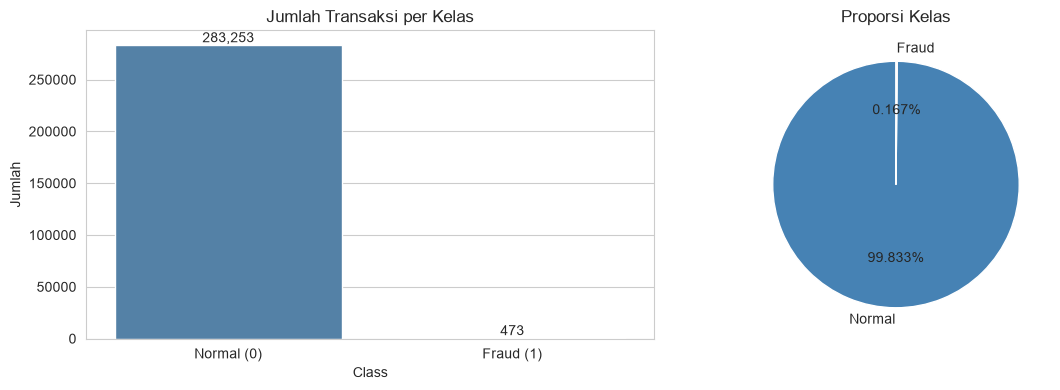

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
sns.countplot(x='Class', data=df, ax=axes[0], palette=['steelblue', 'crimson'])
axes[0].set_title('Jumlah Transaksi per Kelas')
axes[0].set_xticklabels(['Normal (0)', 'Fraud (1)'])
axes[0].set_ylabel('Jumlah')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')

# Pie chart
axes[1].pie(class_count, labels=['Normal', 'Fraud'],
            autopct='%1.3f%%', colors=['steelblue', 'crimson'],
            startangle=90)
axes[1].set_title('Proporsi Kelas')

plt.tight_layout()
plt.show()

## 3. Split Data & Scaling

### 3.1 Train-Test Split

In [34]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

print("\nDistribusi y_train:")
print(y_train.value_counts())
print(f"Proporsi fraud di train: {y_train.mean()*100:.4f}%")

print("\nDistribusi y_test:")
print(y_test.value_counts())
print(f"Proporsi fraud di test : {y_test.mean()*100:.4f}%")

Shape X_train: (226980, 30)
Shape X_test : (56746, 30)

Distribusi y_train:
Class
0    226602
1       378
Name: count, dtype: int64
Proporsi fraud di train: 0.1665%

Distribusi y_test:
Class
0    56651
1       95
Name: count, dtype: int64
Proporsi fraud di test : 0.1674%


### 3.2 Feature Scaling

In [35]:
scaler = StandardScaler()

# Fit di train, transform di train & test
X_train[['Time', 'Amount']] = scaler.fit_transform(X_train[['Time', 'Amount']])
X_test[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

print("Statistik setelah scaling (data train):")
X_train[['Time', 'Amount']].describe().round(4)

Statistik setelah scaling (data train):


,Time,Amount
count,226980.0000,226980.0000
mean,-0.0000,0.0000
std,1.0000,1.0000
min,-1.9984,-0.3596
25%,-0.8562,-0.3365
50%,-0.2124,-0.2698
75%,0.9363,-0.0429
max,1.6402,79.6209


## 4. Penanganan Class Imbalance dengan SMOTE

In [36]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Distribusi sebelum SMOTE:")
print(y_train.value_counts())
print(f"Rasio: {y_train.value_counts()[0] / y_train.value_counts()[1]:.2f} : 1")

print("\nDistribusi setelah SMOTE:")
print(y_train_res.value_counts())
print(f"Rasio: {y_train_res.value_counts()[0] / y_train_res.value_counts()[1]:.2f} : 1")

Distribusi sebelum SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64
Rasio: 599.48 : 1

Distribusi setelah SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64
Rasio: 1.00 : 1


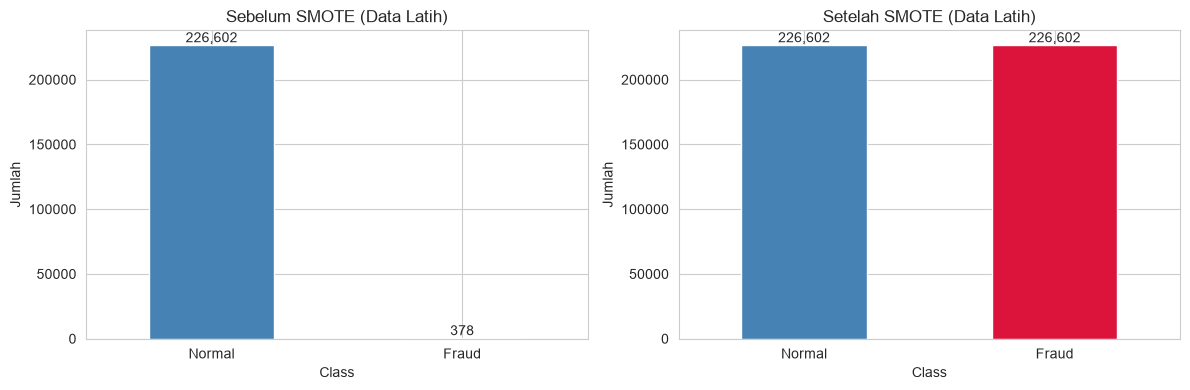

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y_train.value_counts().plot(kind='bar', ax=axes[0],
                             color=['steelblue', 'crimson'])
axes[0].set_title('Sebelum SMOTE (Data Latih)')
axes[0].set_xticklabels(['Normal', 'Fraud'], rotation=0)
axes[0].set_ylabel('Jumlah')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')

y_train_res.value_counts().plot(kind='bar', ax=axes[1],
                                 color=['steelblue', 'crimson'])
axes[1].set_title('Setelah SMOTE (Data Latih)')
axes[1].set_xticklabels(['Normal', 'Fraud'], rotation=0)
axes[1].set_ylabel('Jumlah')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')

plt.tight_layout()
plt.show()

**Insight:**

Setelah SMOTE, jumlah sampel kelas fraud di data latih naik signifikan sehingga rasio kelas menjadi **1:1**. Ini membuat model tidak lagi bias ke kelas mayoritas saat training.

Perlu dicatat bahwa SMOTE **tidak menambah informasi baru** — ia hanya membuat sampel sintetis berdasarkan pola yang sudah ada. Kualitas sampel sintetis sangat bergantung pada distribusi kelas minoritas asli.

Data uji **tidak** disentuh oleh SMOTE, sehingga evaluasi tetap mencerminkan kondisi dunia nyata yang sangat tidak seimbang.

## 5. Membangun Model Ensemble

| Model | Skenario |
|-------|----------|
| Random Forest | Tanpa SMOTE |
| Random Forest | Dengan SMOTE |
| Gradient Boosting | Tanpa SMOTE |
| Gradient Boosting | Dengan SMOTE |

**Hyperparameter yang digunakan:**
- `n_estimators=100` → jumlah tree, cukup untuk dataset ini
- `max_depth` dibatasi → mencegah overfitting pada data fraud
- `class_weight='balanced'` (khusus skenario tanpa SMOTE) → memberi bobot lebih besar pada kelas minoritas, sebagai alternatif penanganan imbalance tanpa resampling

**Metrik evaluasi:** Precision, Recall, F1-Score, AUC-ROC (fokus pada kelas Fraud = 1).

### 5.1 Fungsi Evaluasi

In [39]:
def evaluate_model(model, X_test, y_test, model_name, show_cm=True):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)

    print(f"{'='*55}")
    print(f"Model: {model_name}")
    print(f"{'='*55}")
    print(classification_report(y_test, y_pred,
                                target_names=['Normal', 'Fraud'],
                                digits=4))

    if show_cm:
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Normal', 'Fraud'],
                    yticklabels=['Normal', 'Fraud'])
        plt.title(f'Confusion Matrix - {model_name}')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.show()

    return {
        'Model': model_name,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'AUC-ROC': round(auc, 4),
        'AUC-PR': round(ap, 4)
    }

`predict()` menggunakan threshold 0.5 untuk memutuskan kelas. Pada kasus fraud detection, threshold ini sering **tidak optimal** karena:
- Threshold tinggi → precision tinggi, tapi recall rendah (banyak fraud lolos)
- Threshold rendah → recall tinggi, tapi precision rendah (banyak false alarm)

### 5.2 Random Forest — Tanpa SMOTE

In [40]:
start = time.time()

rf_base = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_base.fit(X_train, y_train)

print(f"Waktu training: {time.time()-start:.2f} detik")

Waktu training: 6.91 detik


Model: RF - Tanpa SMOTE (class_weight=balanced)
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9997     56651
       Fraud     0.9211    0.7368    0.8187        95

    accuracy                         0.9995     56746
   macro avg     0.9603    0.8684    0.9092     56746
weighted avg     0.9994    0.9995    0.9994     56746



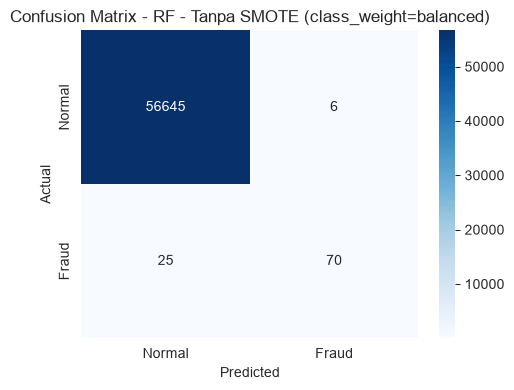

In [41]:
result_rf_base = evaluate_model(
    rf_base, X_test, y_test,
    'RF - Tanpa SMOTE (class_weight=balanced)'
)

### 5.3 Random Forest — Dengan SMOTE

In [42]:
start = time.time()

rf_smote = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
rf_smote.fit(X_train_res, y_train_res)

print(f"Waktu training: {time.time()-start:.2f} detik")

Waktu training: 26.34 detik


Model: RF - Dengan SMOTE
              precision    recall  f1-score   support

      Normal     0.9996    0.9996    0.9996     56651
       Fraud     0.7629    0.7789    0.7708        95

    accuracy                         0.9992     56746
   macro avg     0.8813    0.8893    0.8852     56746
weighted avg     0.9992    0.9992    0.9992     56746



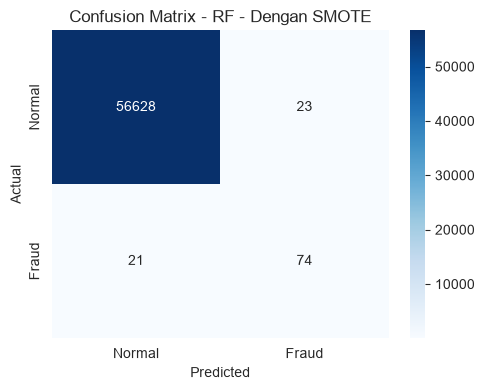

In [43]:
result_rf_smote = evaluate_model(
    rf_smote, X_test, y_test,
    'RF - Dengan SMOTE'
)

### 5.4 Gradient Boosting — Tanpa SMOTE

In [44]:
sample_weights = np.where(y_train == 1, 10.0, 1.0)

start = time.time()

gb_base = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
gb_base.fit(X_train, y_train, sample_weight=sample_weights)

print(f"Waktu training: {time.time()-start:.2f} detik")

Waktu training: 388.64 detik


Model: GB - Tanpa SMOTE (sample_weight)
              precision    recall  f1-score   support

      Normal     0.9995    0.9997    0.9996     56651
       Fraud     0.8072    0.7053    0.7528        95

    accuracy                         0.9992     56746
   macro avg     0.9034    0.8525    0.8762     56746
weighted avg     0.9992    0.9992    0.9992     56746



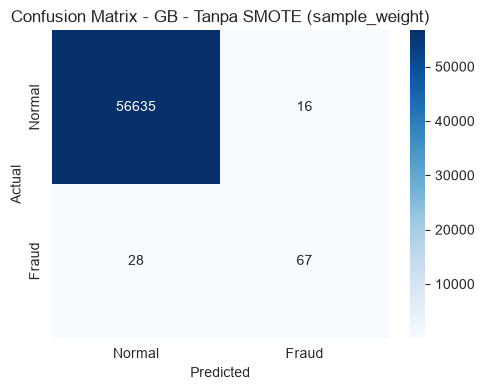

In [45]:
result_gb_base = evaluate_model(
    gb_base, X_test, y_test,
    'GB - Tanpa SMOTE (sample_weight)'
)

### 5.5 Gradient Boosting — Dengan SMOTE

In [46]:
start = time.time()

gb_smote = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
gb_smote.fit(X_train_res, y_train_res)

print(f"Waktu training: {time.time()-start:.2f} detik")

Waktu training: 776.15 detik


Model: GB - Dengan SMOTE
              precision    recall  f1-score   support

      Normal     0.9997    0.9973    0.9985     56651
       Fraud     0.3419    0.8421    0.4863        95

    accuracy                         0.9970     56746
   macro avg     0.6708    0.9197    0.7424     56746
weighted avg     0.9986    0.9970    0.9976     56746



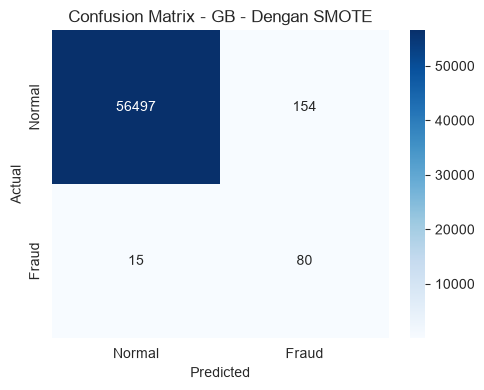

In [47]:
result_gb_smote = evaluate_model(
    gb_smote, X_test, y_test,
    'GB - Dengan SMOTE'
)

## 6. Perbandingan Hasil Model

Metrik yang dibandingkan:
- **Precision** 
- **Recall** 
- **F1-Score** 
- **AUC-ROC**
- **AUC-PR** 

In [48]:
results = pd.DataFrame([
    result_rf_base,
    result_rf_smote,
    result_gb_base,
    result_gb_smote
])

results

,Model,Precision,Recall,F1-Score,AUC-ROC,AUC-PR
0,RF - Tanpa SMOTE (class_weight=balanced),0.9211,0.7368,0.8187,0.9559,0.8020
1,RF - Dengan SMOTE,0.7629,0.7789,0.7708,0.9771,0.8030
2,GB - Tanpa SMOTE (sample_weight),0.8072,0.7053,0.7528,0.9690,0.5956
3,GB - Dengan SMOTE,0.3419,0.8421,0.4863,0.9742,0.6837


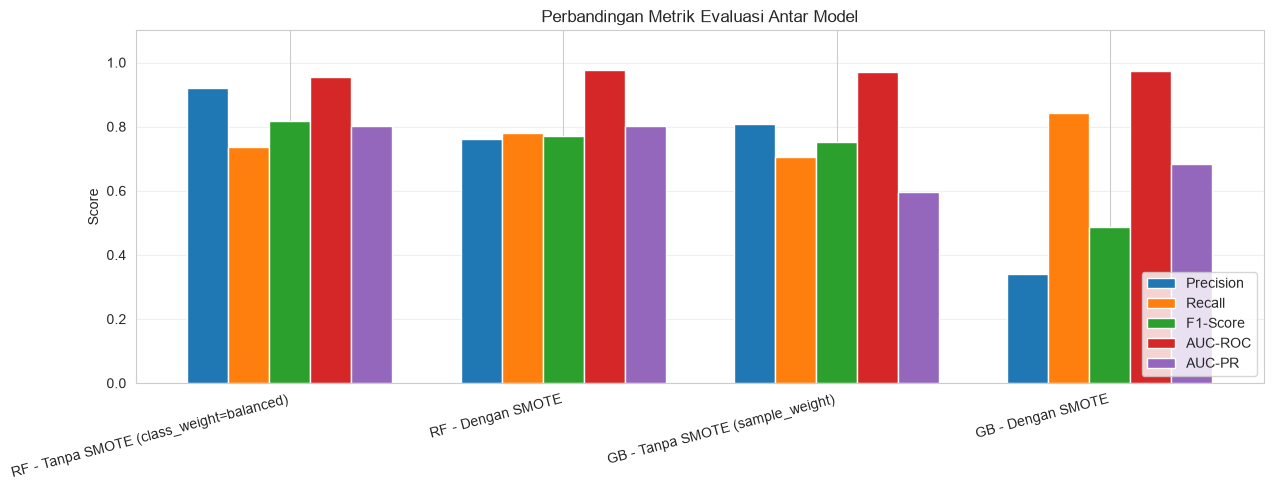

In [49]:
metrics = ['Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'AUC-PR']
x = np.arange(len(results))
width = 0.15

fig, ax = plt.subplots(figsize=(13, 5))
for i, m in enumerate(metrics):
    ax.bar(x + i*width, results[m], width, label=m)

ax.set_xticks(x + width*2)
ax.set_xticklabels(results['Model'], rotation=15, ha='right')
ax.set_ylabel('Score')
ax.set_title('Perbandingan Metrik Evaluasi Antar Model')
ax.legend(loc='lower right')
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

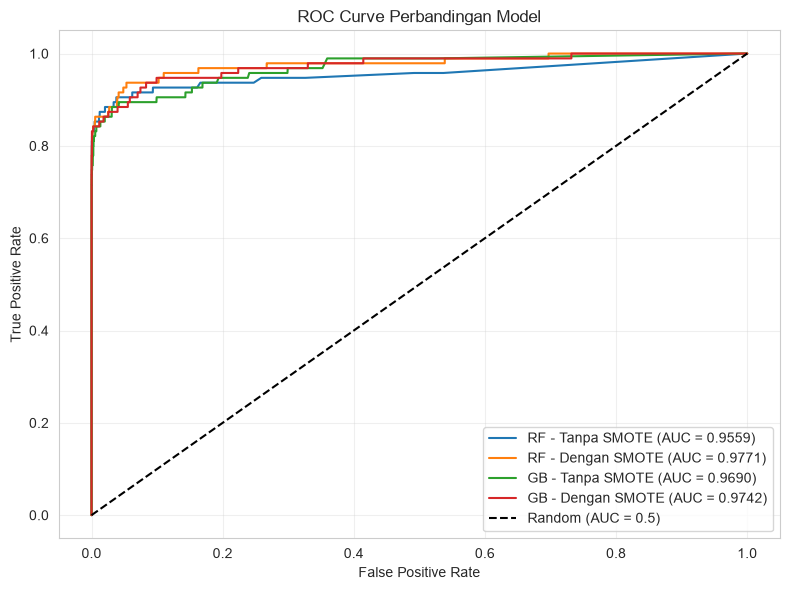

In [50]:
plt.figure(figsize=(8, 6))

models_dict = {
    'RF - Tanpa SMOTE': rf_base,
    'RF - Dengan SMOTE': rf_smote,
    'GB - Tanpa SMOTE': gb_base,
    'GB - Dengan SMOTE': gb_smote
}

for name, model in models_dict.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Perbandingan Model')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

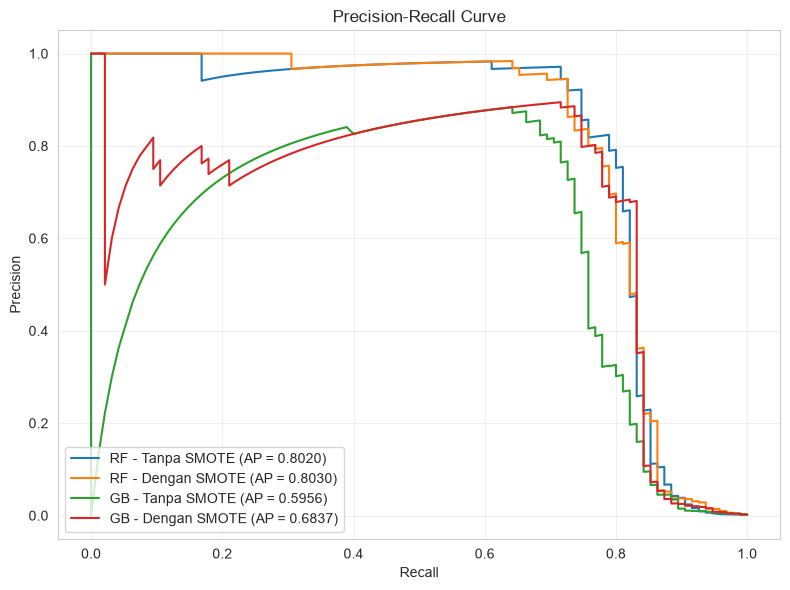

In [51]:
plt.figure(figsize=(8, 6))

for name, model in models_dict.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    plt.plot(rec, prec, label=f'{name} (AP = {ap:.4f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.1 Threshold Tuning

In [52]:
# Best Model Selection
y_proba_best = rf_smote.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.05)
rows = []
for t in thresholds:
    y_pred_t = (y_proba_best >= t).astype(int)
    rows.append({
        'Threshold': round(t, 2),
        'Precision': round(precision_score(y_test, y_pred_t, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred_t), 4),
        'F1-Score': round(f1_score(y_test, y_pred_t), 4)
    })

thr_df = pd.DataFrame(rows)
thr_df

,Threshold,Precision,Recall,F1-Score
0,0.10,0.0946,0.8632,0.1705
1,0.15,0.1855,0.8632,0.3054
2,0.20,0.2867,0.8421,0.4278
3,0.25,0.4317,0.8316,0.5683
4,0.30,0.5342,0.8211,0.6473
5,0.35,0.6080,0.8000,0.6909
6,0.40,0.6972,0.8000,0.7451
7,0.45,0.7282,0.7895,0.7576
8,0.50,0.7629,0.7789,0.7708
9,0.55,0.8000,0.7579,0.7784


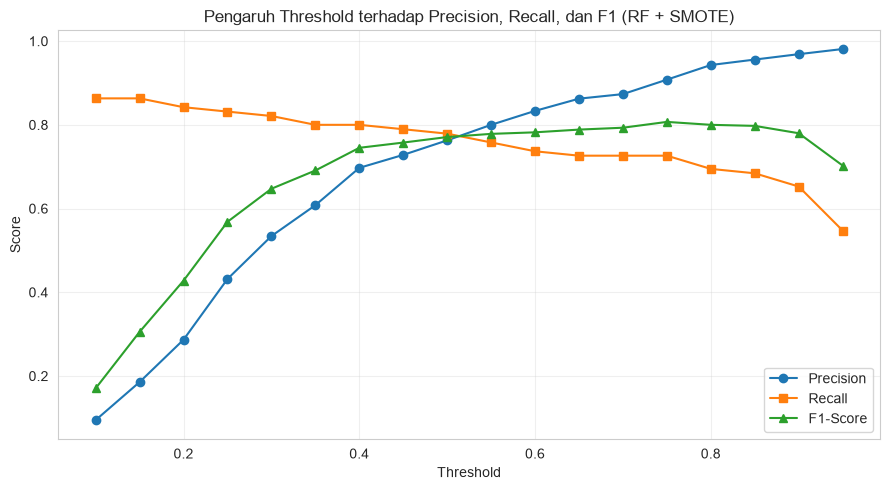

Threshold terbaik berdasarkan F1: 0.75
  Precision : 0.9079
  Recall    : 0.7263
  F1-Score  : 0.807


In [53]:
plt.figure(figsize=(9, 5))
plt.plot(thr_df['Threshold'], thr_df['Precision'], marker='o', label='Precision')
plt.plot(thr_df['Threshold'], thr_df['Recall'], marker='s', label='Recall')
plt.plot(thr_df['Threshold'], thr_df['F1-Score'], marker='^', label='F1-Score')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Pengaruh Threshold terhadap Precision, Recall, dan F1 (RF + SMOTE)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Threshold dengan F1 terbaik
best_row = thr_df.loc[thr_df['F1-Score'].idxmax()]
print(f"Threshold terbaik berdasarkan F1: {best_row['Threshold']}")
print(f"  Precision : {best_row['Precision']}")
print(f"  Recall    : {best_row['Recall']}")
print(f"  F1-Score  : {best_row['F1-Score']}")